# Simulador Estatístico da Reta Final do Brasileirão Série A 2026

**Autor:** Henrique Mendes Elias (Universidade de Brasília — UnB)  
**Áreas Integradas:** Engenharia de Dados (ETL com Pandas) • Ciência de Dados (Distribuição de Poisson & Simulação de Monte Carlo com NumPy/SciPy) • Análise de Dados & BI (Storytelling Visual com Matplotlib/Seaborn)

---

## 1. Contextualização e Problema de Negócio

Como prever de forma matematicamente rigorosa o desfecho de um campeonato de pontos corridos quando restam 42 partidas e dezenas de trilhões ($3^{42} \approx 1.09 \times 10^{20}$) de combinações possíveis de resultados?

Este notebook documenta passo a passo a construção do **motor preditivo do Brasileirão 2026**, dividido em três frentes:
1. **Engenharia de Dados (`src/data_engineering`)**: Ingestão do histórico bruto (`data/raw/BRA.csv`), descarte de variáveis externas (odds de casas de apostas) na leitura, padronização de nomenclatura e cálculo dos **Índices de Força Relativa de Ataque e Defesa** ponderados pelo mando de campo.
2. **Ciência de Dados (`src/data_science`)**:
   - **Modelo de Partida Única (Distribuição de Poisson)**: Estima a expectativa de gols ($\lambda_{mandante}, \lambda_{visitante}$) e constrói a matriz de probabilidades conjuntas $9 \times 9$ ($0$ a $8$ gols) para extrair o **Placar Mais Provável** e as probabilidades de Vitória, Empate e Derrota.
   - **Projeção do Campeonato (Simulação de Monte Carlo)**: Aplica a **Lei dos Grandes Números** simulando de forma 100% vetorizada em NumPy os 42 jogos restantes **10.000 vezes**, ordenando a tabela final pelos 4 critérios oficiais da CBF (*Pontos > Vitórias > Saldo de Gols > Gols Pró*).
3. **Business Intelligence (`src/bi_analytics`)**: Tradução das 10.000 simulações em 4 visões executivas para tomada de decisão e análise esportiva.

In [1]:
import sys
from pathlib import Path

# Adiciona a raiz do projeto ao sys.path para importar os módulos de `src/`
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_engineering.etl import (
    carregar_partidas_realizadas,
    carregar_jogos_restantes,
    calcular_metricas_liga,
    construir_tabela_e_forcas,
)
from src.data_science.poisson import (
    prever_confronto_poisson,
    prever_todos_jogos_restantes,
)
from src.data_science.monte_carlo import executar_simulacao_monte_carlo
from src.bi_analytics.graficos import (
    plotar_corrida_titulo,
    plotar_termometro_z4,
    plotar_distribuicao_pontos,
    plotar_matriz_quadrantes_forcas,
)

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 1000)

---
## 2. Engenharia de Dados: ETL, Limpeza e Forças Relativas

O arquivo bruto `data/raw/BRA.csv` contém **338 partidas realizadas** até o dia `05/11/2026`, além de dezenas de colunas de cotações de apostas (*odds*). Para garantir um modelo 100% autoral e otimizar o uso de memória, filtramos na leitura (`usecols`) apenas os dados factuais da partida e enriquecemos cada confronto com:
- Nome Oficial em Português;
- Sigla Oficial de 3 letras (padrão GE/CBF);
- Estádio Sede do Mandante.

In [2]:
df_partidas = carregar_partidas_realizadas()
df_restantes = carregar_jogos_restantes()
metricas_liga = calcular_metricas_liga(df_partidas)

print(f"Partidas realizadas: {len(df_partidas)} | Partidas restantes: {len(df_restantes)} | Total: {len(df_partidas) + len(df_restantes)}")
print(f"Média de Gols do Mandante na Liga (mu_mandante):  {metricas_liga['media_gols_mandante']:.4f} gols/jogo")
print(f"Média de Gols do Visitante na Liga (mu_visitante): {metricas_liga['media_gols_visitante']:.4f} gols/jogo")
df_partidas.tail(8)

Partidas realizadas: 339 | Partidas restantes: 41 | Total: 380
Média de Gols do Mandante na Liga (mu_mandante):  1.5398 gols/jogo
Média de Gols do Visitante na Liga (mu_visitante): 1.1327 gols/jogo


,rodada,data,horario,mandante,visitante,gols_mandante,gols_visitante,resultado,sigla_mandante,sigla_visitante,estadio
331,34,03/11/2026,21:30,Internacional,Coritiba,1,0,H,INT,CFC,Beira-Rio
332,34,04/11/2026,19:30,Athletico-PR,Vasco da Gama,1,3,A,CAP,VAS,Arena da Baixada
333,34,04/11/2026,19:30,Flamengo,Grêmio,3,1,H,FLA,GRE,Maracanã
334,34,04/11/2026,21:30,São Paulo,Corinthians,0,0,D,SAO,COR,Morumbis
335,34,04/11/2026,21:30,Botafogo,Atlético-MG,1,0,H,BOT,CAM,Engenhão
336,34,05/11/2026,19:30,Palmeiras,Remo,6,1,H,PAL,REM,Allianz Parque
337,34,05/11/2026,21:30,Cruzeiro,Bahia,3,2,H,CRU,BAH,Mineirão
338,34,06/11/2026,20:00,Vitória,Fluminense,0,3,A,VIT,FLU,Barradão


### 2.1. Classificação Atual e Índices de Força Relativa

Usar a média bruta de gols de um clube ignora o mando de campo e o contexto da liga. Por isso, normalizamos o desempenho ofensivo e defensivo de cada equipe pelas médias gerais da Série A ($\mu_{mandante}$ e $\mu_{visitante}$):

$$\text{ForçaAtaqueMandante}_i = \frac{\text{Gols Pró em Casa}_i / \text{Jogos em Casa}_i}{\mu_{mandante}}, \quad \text{ForçaDefesaMandante}_i = \frac{\text{Gols Sofridos em Casa}_i / \text{Jogos em Casa}_i}{\mu_{visitante}}$$

$$\text{ForçaAtaqueVisitante}_j = \frac{\text{Gols Pró Fora}_j / \text{Jogos Fora}_j}{\mu_{visitante}}, \quad \text{ForçaDefesaVisitante}_j = \frac{\text{Gols Sofridos Fora}_j / \text{Jogos Fora}_j}{\mu_{mandante}}$$

- **Ataque $> 1.0$**: O clube marca mais gols que a média da liga naquela condição.
- **Defesa $< 1.0$**: O clube sofre **menos** gols que a média da liga (defesa mais sólida).

In [3]:
df_tabela_atual = construir_tabela_e_forcas(df_partidas, metricas_liga)
colunas_tabela = [
    "posicao", "clube", "sigla", "pontos", "jogos", "vitorias", "empates", "derrotas",
    "gols_pro", "gols_contra", "saldo_gols", "aproveitamento",
    "forca_ataque_mandante", "forca_defesa_mandante", "forca_ataque_visitante", "forca_defesa_visitante"
]
df_tabela_atual[colunas_tabela]

,posicao,clube,sigla,pontos,jogos,vitorias,empates,derrotas,gols_pro,gols_contra,saldo_gols,aproveitamento,forca_ataque_mandante,forca_defesa_mandante,forca_ataque_visitante,forca_defesa_visitante
0,1,Flamengo,FLA,76,34,23,7,4,71,29,42,74.5,1.337052,0.675092,1.869485,0.611224
1,2,Palmeiras,PAL,73,34,21,10,3,62,23,39,71.6,1.375254,0.571232,1.350184,0.458418
2,3,Cruzeiro,CRU,60,34,18,6,10,55,48,7,58.8,1.146045,0.934743,1.298254,1.146045
3,4,Fluminense,FLU,57,34,16,9,9,55,42,13,55.9,1.184246,0.882812,1.246324,0.955037
4,5,Athletico-PR,CAP,54,34,15,9,10,51,43,8,52.9,1.069642,0.934743,1.194393,0.955037
5,6,Bahia,BAH,53,34,14,11,9,50,45,5,52.0,0.993239,0.986673,1.246324,0.993239
6,7,Atlético-MG,CAM,50,34,14,8,12,44,40,4,49.0,1.031440,0.934743,0.882812,0.840433
7,8,Red Bull Bragantino,RBB,47,34,13,8,13,44,39,5,46.1,1.107843,0.934743,0.778952,0.802231
8,9,Santos,SAN,47,34,12,11,11,50,49,1,46.1,0.878634,1.090533,1.402114,1.069642
9,10,São Paulo,SAO,44,34,12,8,14,39,39,0,43.1,0.955037,0.675092,0.727022,0.993239


---
## 3. Ciência de Dados: Distribuição de Poisson (Previsão de Jogo Único)

Para cada confronto restante entre o Mandante $i$ e o Visitante $j$, calculamos a expectativa de gols ($\lambda$) cruzando o ataque de um com a defesa do outro:

$$\lambda_{mandante} = \text{ForçaAtaqueMandante}_i \times \text{ForçaDefesaVisitante}_j \times \mu_{mandante}$$
$$\lambda_{visitante} = \text{ForçaAtaqueVisitante}_j \times \text{ForçaDefesaMandante}_i \times \mu_{visitante}$$

A probabilidade de cada placar exato $(x, y)$ para $x, y \in \{0, 1, \dots, 8\}$ é dada pelo produto das distribuições de Poisson:

$$P(\text{Mandante} = x, \text{Visitante} = y) = \left( \frac{\lambda_m^x e^{-\lambda_m}}{x!} \right) \times \left( \frac{\lambda_v^y e^{-\lambda_v}}{y!} \right)$$

Vamos inspecionar na prática a matriz de probabilidades para o confronto direto pelo título da **36ª Rodada: Palmeiras x Flamengo**:

In [4]:
exemplo_classico = prever_confronto_poisson("Palmeiras", "Flamengo", df_tabela_atual, metricas_liga)
print(f"Confronto: {exemplo_classico['mandante']} vs {exemplo_classico['visitante']}")
print(f"Expectativa de Gols (Lambda): Palmeiras = {exemplo_classico['lambda_mandante']} | Flamengo = {exemplo_classico['lambda_visitante']}")
print(f"Placar Mais Provável (Moda de Poisson): {exemplo_classico['placar_provavel']} ({exemplo_classico['prob_placar_provavel']}%)")
print(f"Probabilidades 1X2 -> Vitória Palmeiras: {exemplo_classico['prob_vitoria_mandante']}% | Empate: {exemplo_classico['prob_empate']}% | Vitória Flamengo: {exemplo_classico['prob_vitoria_visitante']}%")

# Exibe recorte 5x5 (0 a 4 gols) da matriz de placares em percentual
df_matriz_5x5 = pd.DataFrame(
    np.round(exemplo_classico["matriz_placares"][:5, :5] * 100, 2),
    index=[f"PAL {i}" for i in range(5)],
    columns=[f"FLA {j}" for j in range(5)],
)
df_matriz_5x5

Confronto: Palmeiras vs Flamengo
Expectativa de Gols (Lambda): Palmeiras = 1.294356282066579 | Flamengo = 1.2096669550173011
Placar Mais Provável (Moda de Poisson): 1x1 (12.800951792068538%)
Probabilidades 1X2 -> Vitória Palmeiras: 38.54110779213847% | Empate: 26.949961025832447% | Vitória Flamengo: 34.50893118202909%


,FLA 0,FLA 1,FLA 2,FLA 3,FLA 4
PAL 0,8.18,9.89,5.98,2.41,0.73
PAL 1,10.58,12.80,7.74,3.12,0.94
PAL 2,6.85,8.28,5.01,2.02,0.61
PAL 3,2.95,3.57,2.16,0.87,0.26
PAL 4,0.96,1.16,0.70,0.28,0.09


In [5]:
# Previsão de Poisson para todos os 42 jogos restantes do campeonato
df_jogos_previstos = prever_todos_jogos_restantes(df_restantes, df_tabela_atual, metricas_liga)
df_jogos_previstos[[
    "rodada", "data", "mandante", "visitante", "lambda_mandante", "lambda_visitante",
    "placar_provavel", "prob_vitoria_mandante", "prob_empate", "prob_vitoria_visitante"
]].head(12)

,rodada,data,mandante,visitante,lambda_mandante,lambda_visitante,placar_provavel,prob_vitoria_mandante,prob_empate,prob_vitoria_visitante
0,21,14/11/2026,Chapecoense,Vasco da Gama,1.451060,2.234619,1x2,24.560001,20.168847,55.271152
1,35,14/11/2026,Mirassol,Atlético-MG,1.186493,1.142463,1x1,37.006334,28.150624,34.843041
2,35,18/11/2026,Coritiba,Santos,1.384242,1.732023,1x1,30.814644,23.407421,45.777935
3,35,18/11/2026,Remo,Chapecoense,1.581991,0.739241,1x0,57.518371,25.120480,17.361148
4,35,18/11/2026,Flamengo,Athletico-PR,1.966253,0.913360,1x0,61.937010,21.245812,16.817178
5,35,18/11/2026,Cruzeiro,Palmeiras,0.808973,1.429606,0x1,21.242620,27.048681,51.708700
6,35,18/11/2026,Corinthians,Botafogo,1.253908,0.986673,1x0,42.412469,28.479860,29.107672
7,35,18/11/2026,Grêmio,Bahia,1.577497,1.539576,1x1,38.932178,23.774429,37.293394
8,35,19/11/2026,Vasco da Gama,Internacional,1.404466,1.173010,1x1,42.273338,26.313876,31.412786
9,35,19/11/2026,Vitória,Red Bull Bragantino,1.085372,0.733131,1x0,43.553385,31.946296,24.500319


---
## 4. Ciência de Dados: Simulação de Monte Carlo (10.000 Campeonatos)

Com os parâmetros $\lambda_{mandante}$ e $\lambda_{visitante}$ dos 42 jogos restantes, executamos **10.000 simulações estocásticas vetorizadas** no NumPy (`seed=42` para reprodutibilidade científica). Em cada iteração:
1. Os 42 placares são sorteados segundo suas distribuições de Poisson;
2. Os pontos, vitórias, saldo de gols e gols pró são somados à tabela atual;
3. A classificação final das 10.000 temporadas é ordenada pelos 4 critérios oficiais da CBF.

In [6]:
resultado_mc = executar_simulacao_monte_carlo(
    df_tabela_atual=df_tabela_atual,
    df_jogos_previstos=df_jogos_previstos,
    n_simulacoes=10_000,
    seed=42,
)

df_resumo_final = resultado_mc["df_resumo"]
colunas_resumo = [
    "posicao", "clube", "pontos", "jogos", "vitorias", "empates", "derrotas", "saldo_gols",
    "media_pontos_mc", "prob_titulo", "prob_libertadores", "prob_sulamericana", "prob_rebaixamento",
    "rotulo_coluna_inteligente", "valor_coluna_inteligente"
]
df_resumo_final[colunas_resumo]

,posicao,clube,pontos,jogos,vitorias,empates,derrotas,saldo_gols,media_pontos_mc,prob_titulo,prob_libertadores,prob_sulamericana,prob_rebaixamento,rotulo_coluna_inteligente,valor_coluna_inteligente
0,1,Flamengo,86,38,26,8,4,47,84.3,83.42,100.00,0.00,0.00,Título,83.42
1,2,Palmeiras,83,38,24,11,3,45,81.4,16.58,100.00,0.00,0.00,Título,16.58
2,3,Cruzeiro,66,38,20,6,12,7,65.9,0.00,99.99,0.01,0.00,Libertadores,99.99
3,4,Fluminense,64,38,18,10,10,14,63.1,0.00,99.27,0.73,0.00,Libertadores,99.27
4,5,Athletico-PR,61,38,17,10,11,10,60.5,0.00,92.23,7.77,0.00,Libertadores,92.23
5,6,Bahia,59,38,15,14,9,6,59.2,0.00,72.49,27.51,0.00,Libertadores,72.49
6,7,Atlético-MG,55,38,15,10,13,4,56.0,0.00,28.48,71.51,0.00,Sul-Americana,71.51
7,8,Santos,53,38,13,14,11,2,53.4,0.00,4.04,95.10,0.00,Sul-Americana,95.10
8,9,São Paulo,50,38,14,8,16,0,49.7,0.00,0.13,93.71,0.00,Sul-Americana,93.71
9,10,Vasco da Gama,50,38,13,11,14,-5,48.4,0.00,0.09,78.62,1.09,Sul-Americana,78.62


---
## 5. Análise de Dados & BI: Visualizações Executivas

### 5.1. Corrida pelo Título (1º Lugar)
Com 3 pontos de vantagem e 2 vitórias a mais que o Palmeiras (1º critério de desempate), o **Flamengo** concentra **83.13%** das probabilidades de título nas 10.000 simulações, contra **16.87%** do **Palmeiras**.

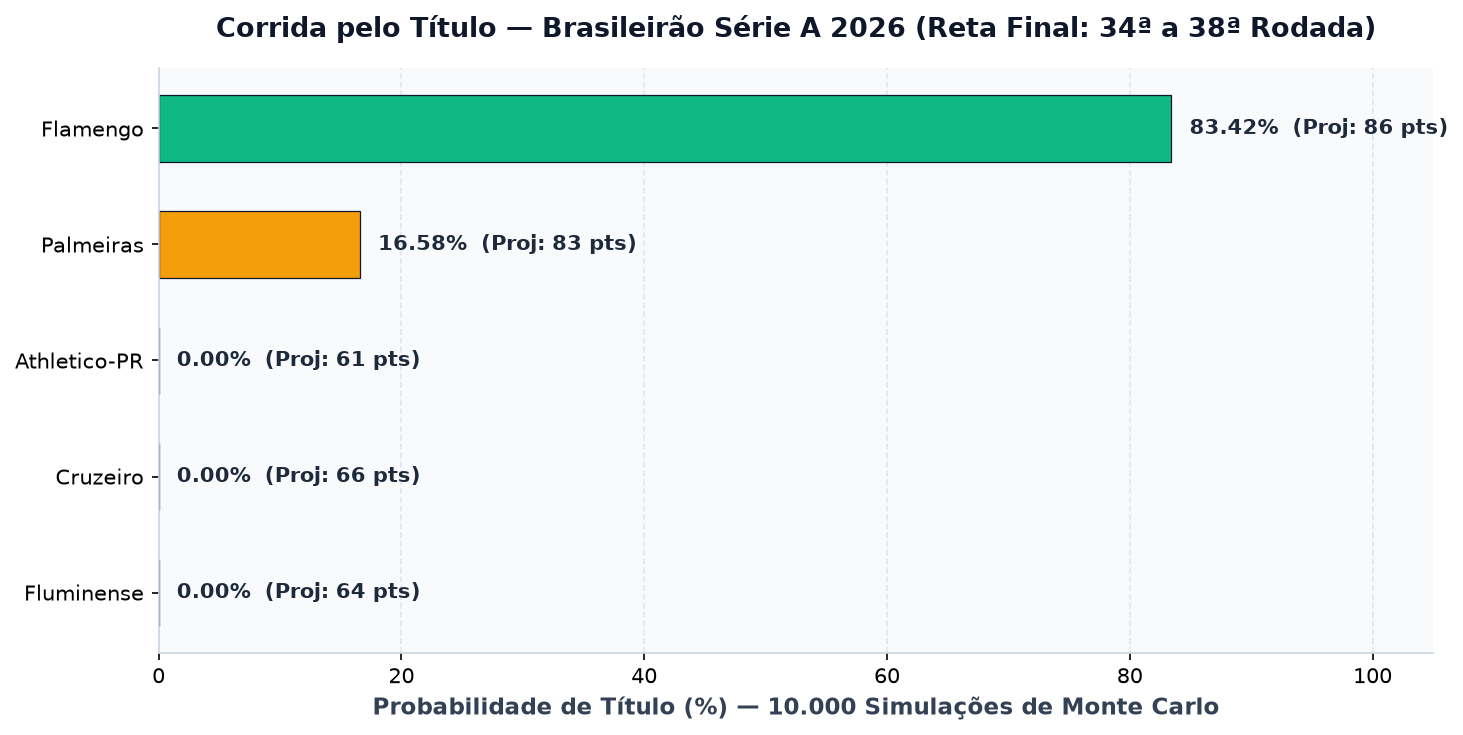

In [7]:
fig1 = plotar_corrida_titulo(df_resumo_final, mostrar=True)
plt.show()

### 5.2. Termômetro da Luta contra o Rebaixamento (Z4)
Enquanto **Chapecoense** (`100%`) e **Remo** (`99.97%`) têm situação matematicamente crítica, as duas vagas restantes do Z4 são disputadas intensamente por **Grêmio**, **Corinthians**, **Internacional**, **Mirassol**, **Vitória** e **Coritiba**.

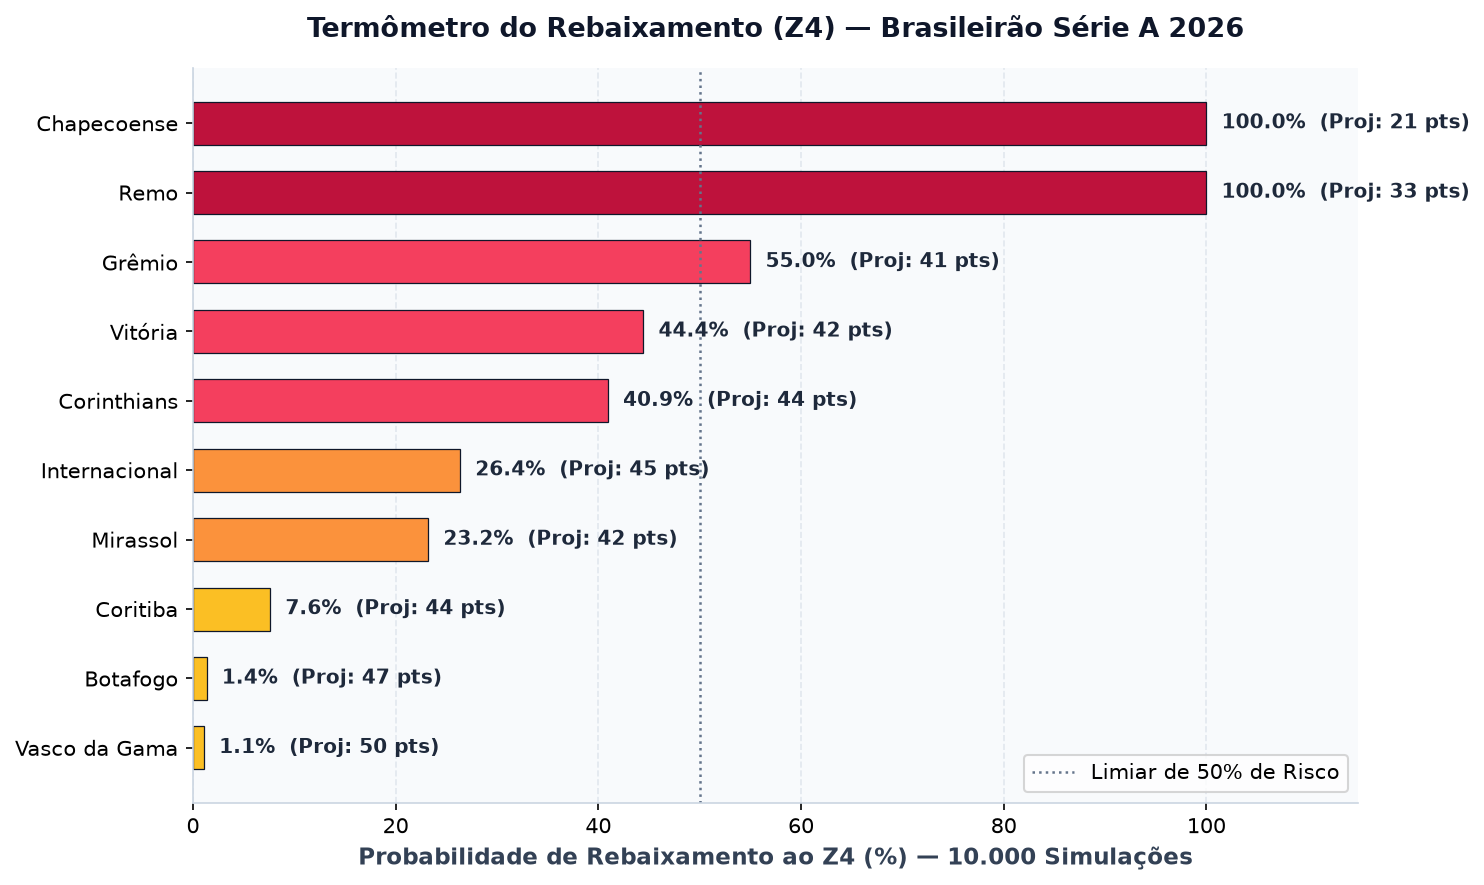

In [8]:
fig2 = plotar_termometro_z4(df_resumo_final, mostrar=True)
plt.show()

### 5.3. Distribuição Probabilística da Pontuação Final (Boxplot 10.000x)
O gráfico de caixa revela a dispersão (intervalo interquartil e mediana) de pontos que cada clube alcança ao fim da 38ª rodada, destacando a linha histórica de corte de **45 pontos** contra o rebaixamento.

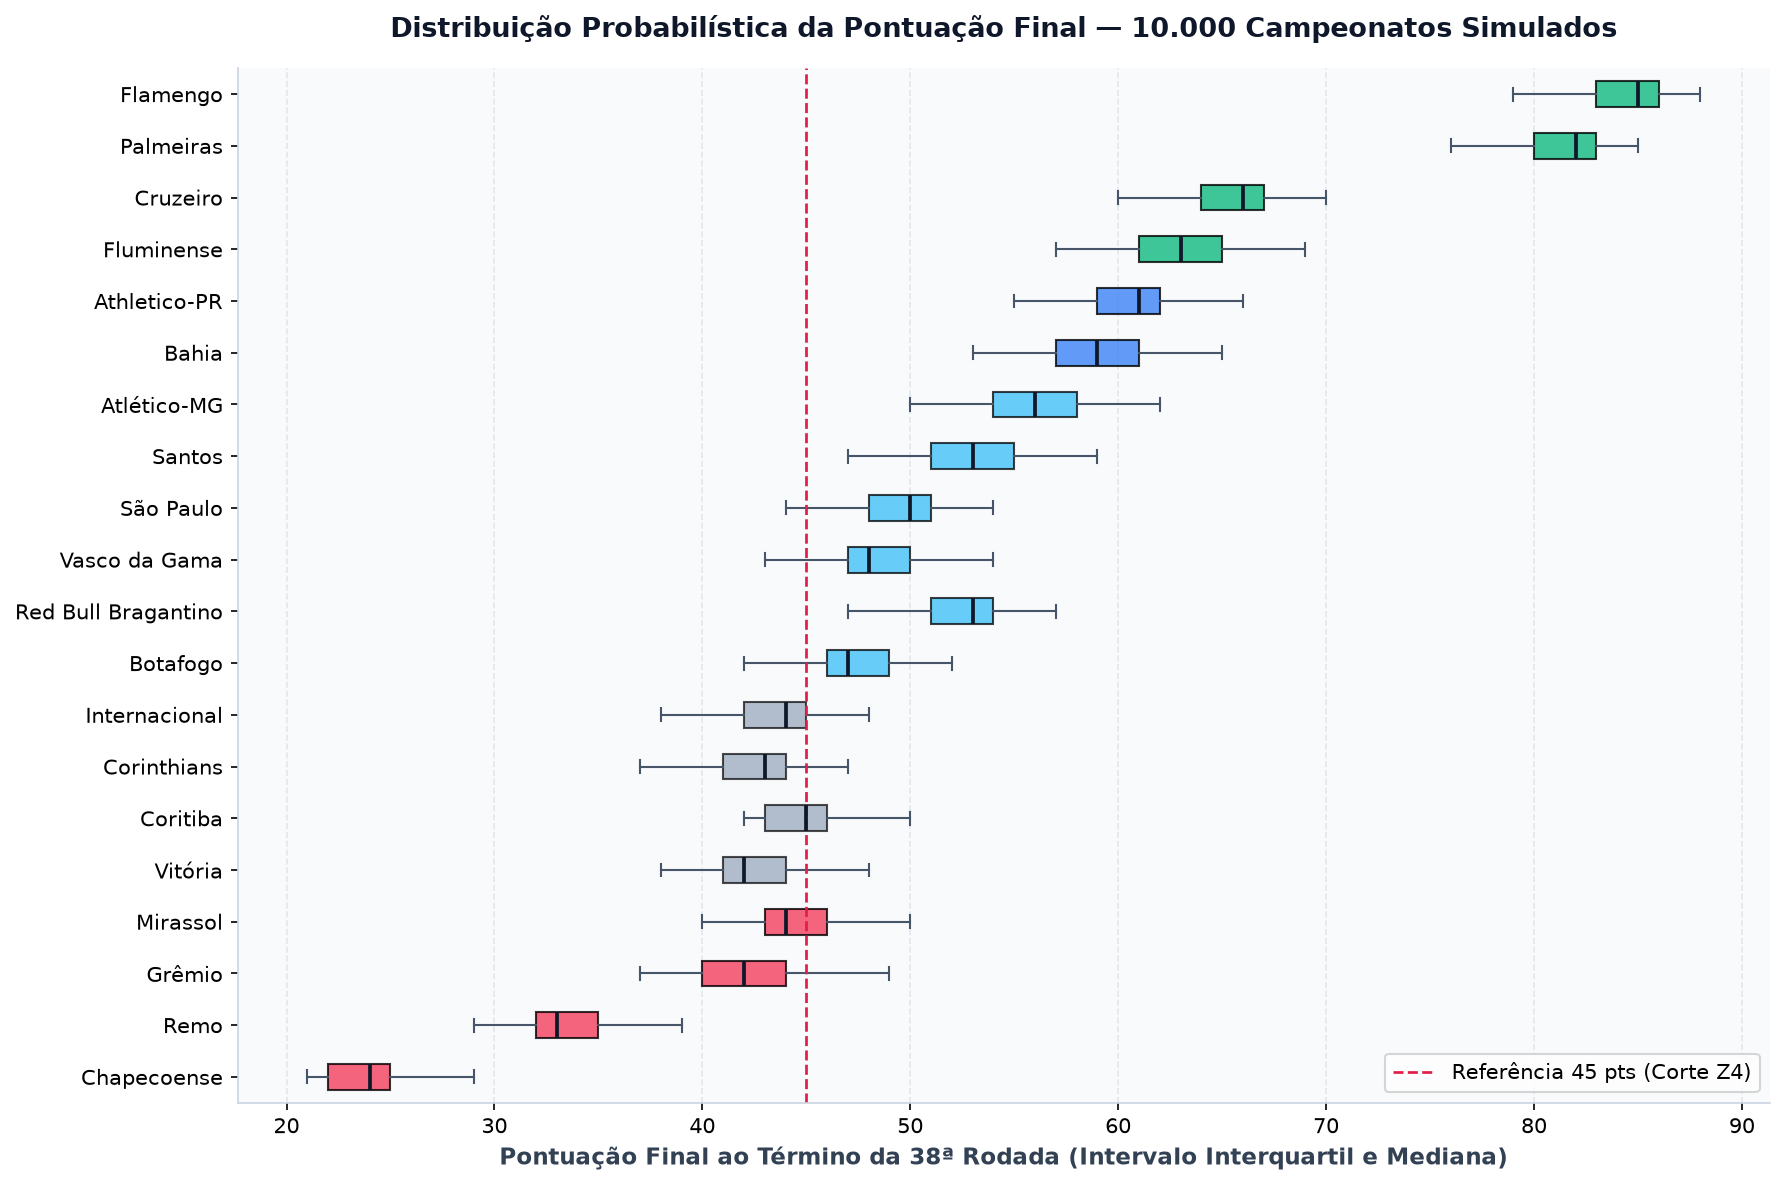

In [9]:
fig3 = plotar_distribuicao_pontos(
    df_resumo_final,
    resultado_mc["matriz_pontos_simulados"],
    resultado_mc["clubes_ordem"],
    mostrar=True,
)
plt.show()

### 5.4. Matriz de Quadrantes: Eficiência Ofensiva vs. Eficiência Defensiva
Cruzando a **Força Relativa de Ataque** (eixo X) com a **Força Relativa de Defesa** (eixo Y invertido, onde valores menores que $1.0$ no topo significam defesas que sofrem menos gols que a média da liga), visualizamos nitidamente o posicionamento estrutural das 20 equipes da Série A.

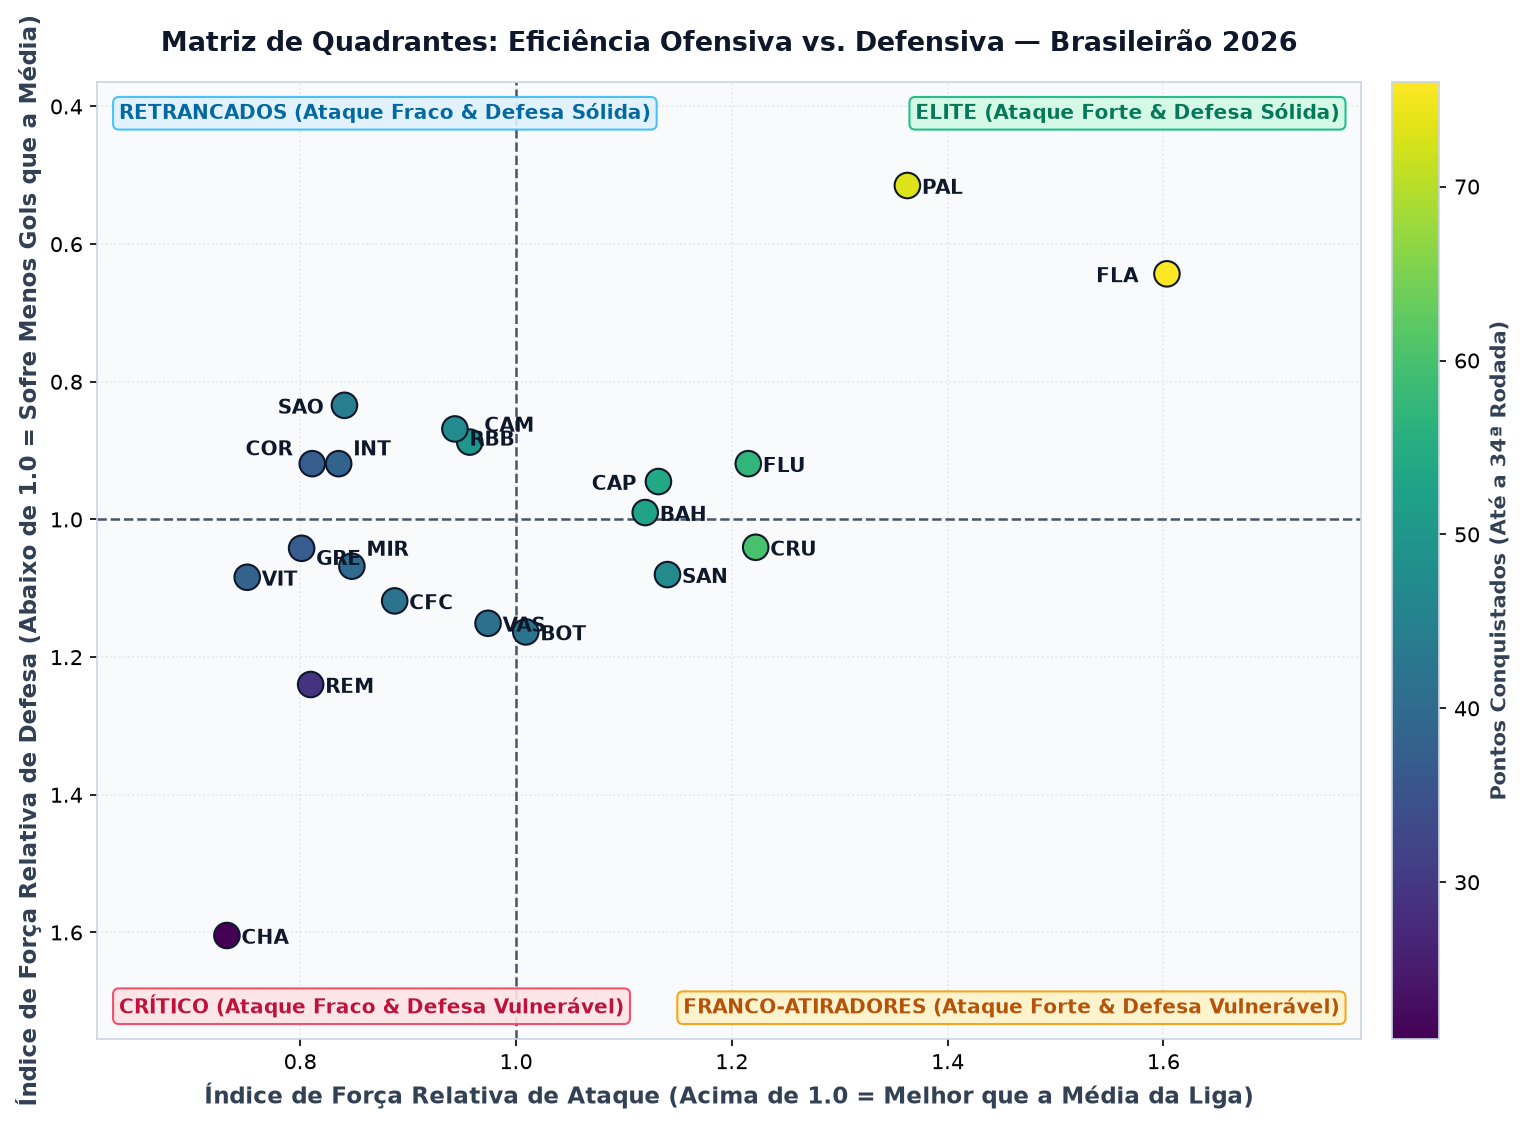

In [10]:
fig4 = plotar_matriz_quadrantes_forcas(df_tabela_atual, mostrar=True)
plt.show()